In [16]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
import smarts_cerebellum.globals as gl

obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_Nettekoven_2024_FaMap.tsv'), sep = '\t')
lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', 'patients_MNISymC_FaMap_Nettekoven_2024_lme.tsv'), sep = '\t')
lme['region_bilat'] = lme['regionname'].astype(str).str[-1]

m_rois = []
a_rois = []
d_rois = []
s_rois = []

for roi in gl.rois['Nettekoven2024']:
    if roi[0] == 'M':
        m_rois.append(roi)
    elif roi[0] == 'A':
        a_rois.append(roi)
    elif roi[0] == 'D':
        d_rois.append(roi)
    elif roi[0] == 'S':
        s_rois.append(roi)
    else:
        print('na')

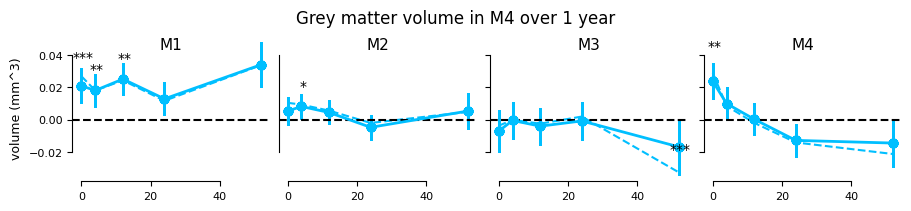

In [38]:
fig, axs = plt.subplots(1, len(m_rois), figsize=(9, 2), sharey = True, constrained_layout = True)

for r, m_roi in enumerate(m_rois):
    lme_m_roi = lme[lme.regionname.str.contains(m_roi)].sort_values('Week')
    obs_m_roi = obs[obs.regionname.str.contains(m_roi)].sort_values('Week')

    obs_m_mean = obs_m_roi.groupby('Week', as_index = False)['asymmetry_index'].mean()
    
    ax = axs[r]
    ax.errorbar(x=lme_m_roi['Week'], y=lme_m_roi['beta'], yerr = lme_m_roi['se'], fmt = '-o',  linewidth = 2, color = 'deepskyblue')
    ax.plot(obs_m_mean['Week'], obs_m_mean['asymmetry_index'], linestyle = '--', color = 'deepskyblue')

    # annotate for significance
    for week in gl.weeks:
        vals = obs_m_roi.loc[obs_m_roi.Week == week, 'asymmetry_index']
        mean, sem = vals.mean(), vals.sem()

        p = stats.ttest_1samp(vals, 0).pvalue
        stars = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
        if stars:
            ax.annotate(stars, xy = (week, mean + sem), xytext = (1, 5), textcoords = 'offset points', ha = 'center')

    ax.axhline(y=0, color = 'black', linestyle = '--')
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_title(m_roi, y = .85)


axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('volume (mm^3)')

fig.suptitle(f'Grey matter volume in {m_roi} over 1 year')
sns.despine(trim = True)


plt.show()


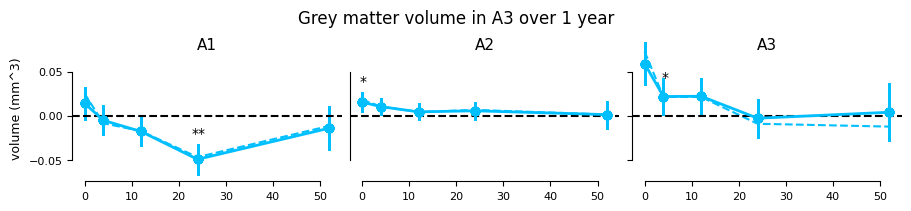

In [ ]:
fig, axs = plt.subplots(1, len(a_rois), figsize=(9, 2), sharey = True, constrained_layout = True)

for r, a_roi in enumerate(a_rois):
    lme_a_roi = lme[lme.regionname.str.contains(a_roi)].sort_values('Week')
    obs_a_roi = obs[obs.regionname.str.contains(a_roi)].sort_values('Week')

    obs_m_mean = obs_a_roi.groupby('Week', as_index = False)['asymmetry_index'].mean()
    
    ax = axs[r]
    ax.errorbar(x=lme_a_roi['Week'], y=lme_a_roi['beta'], yerr = lme_a_roi['se'], fmt = '-o',  linewidth = 2, color = 'blue')
    ax.plot(obs_m_mean['Week'], obs_m_mean['asymmetry_index'], linestyle = '--', color = 'blue')

    # annotate for significance
    for week in gl.weeks:
        vals = obs_a_roi.loc[obs_a_roi.Week == week, 'asymmetry_index']
        mean, sem = vals.mean(), vals.sem()

        p = stats.ttest_1samp(vals, 0).pvalue
        stars = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
        if stars:
            ax.annotate(stars, xy = (week, mean + sem), xytext = (1, 5), textcoords = 'offset points', ha = 'center')

    ax.axhline(y=0, color = 'black', linestyle = '--')
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_title(a_roi, y = .85)


axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('volume (mm^3)')

fig.suptitle(f'Grey matter volume in {a_roi} over 1 year')
sns.despine(trim = True)


plt.show()


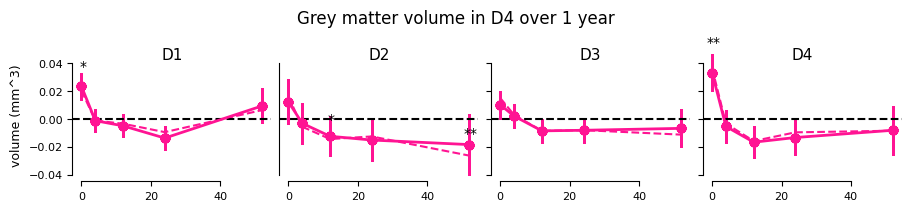

In [40]:
fig, axs = plt.subplots(1, len(d_rois), figsize=(9, 2), sharey = True, constrained_layout = True)

for r, d_roi in enumerate(d_rois):
    lme_d_roi = lme[lme.regionname.str.contains(d_roi)].sort_values('Week')
    obs_d_roi = obs[obs.regionname.str.contains(d_roi)].sort_values('Week')

    obs_m_mean = obs_d_roi.groupby('Week', as_index = False)['asymmetry_index'].mean()
    
    ax = axs[r]
    ax.errorbar(x=lme_d_roi['Week'], y=lme_d_roi['beta'], yerr = lme_d_roi['se'], fmt = '-o',  linewidth = 2, color = 'deeppink')
    ax.plot(obs_m_mean['Week'], obs_m_mean['asymmetry_index'], linestyle = '--', color = 'deeppink')

    # annotate for significance
    for week in gl.weeks:
        vals = obs_d_roi.loc[obs_d_roi.Week == week, 'asymmetry_index']
        mean, sem = vals.mean(), vals.sem()

        p = stats.ttest_1samp(vals, 0).pvalue
        stars = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
        if stars:
            ax.annotate(stars, xy = (week, mean + sem), xytext = (1, 5), textcoords = 'offset points', ha = 'center')

    ax.axhline(y=0, color = 'black', linestyle = '--')
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_title(d_roi, y = .85)


axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('volume (mm^3)')

fig.suptitle(f'Grey matter volume in {d_roi} over 1 year')
sns.despine(trim = True)


plt.show()


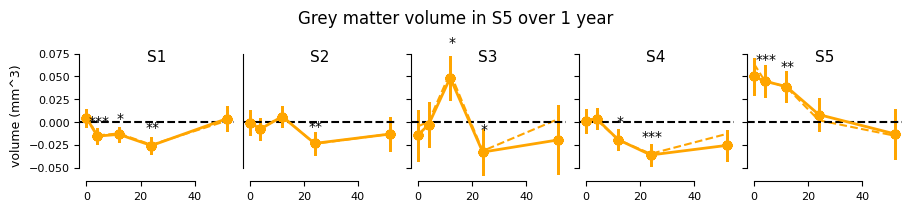

In [41]:
fig, axs = plt.subplots(1, len(s_rois), figsize=(9, 2), sharey = True, constrained_layout = True)

for r, s_roi in enumerate(s_rois):
    lme_s_roi = lme[lme.regionname.str.contains(s_roi)].sort_values('Week')
    obs_s_roi = obs[obs.regionname.str.contains(s_roi)].sort_values('Week')

    obs_m_mean = obs_s_roi.groupby('Week', as_index = False)['asymmetry_index'].mean()
    
    ax = axs[r]
    ax.errorbar(x=lme_s_roi['Week'], y=lme_s_roi['beta'], yerr = lme_s_roi['se'], fmt = '-o',  linewidth = 2, color = 'orange')
    ax.plot(obs_m_mean['Week'], obs_m_mean['asymmetry_index'], linestyle = '--', color = 'orange')

    # annotate for significance
    for week in gl.weeks:
        vals = obs_s_roi.loc[obs_s_roi.Week == week, 'asymmetry_index']
        mean, sem = vals.mean(), vals.sem()

        p = stats.ttest_1samp(vals, 0).pvalue
        stars = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
        if stars:
            ax.annotate(stars, xy = (week, mean + sem), xytext = (1, 5), textcoords = 'offset points', ha = 'center')

    ax.axhline(y=0, color = 'black', linestyle = '--')
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_title(s_roi, y = .85)


axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('volume (mm^3)')

fig.suptitle(f'Grey matter volume in {s_roi} over 1 year')
sns.despine(trim = True)


plt.show()
